
### Variant 50

### Рахаман Мд Афифур
### ИСУ: 407793




In [3]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")

## 1. Load the original data

In [4]:
possible_paths = [
    Path("AY_column.csv"),
]


raw = pd.read_csv("AY_column.csv", header=None)

x = pd.to_numeric(raw.iloc[:, 0], errors="coerce").dropna().to_numpy(dtype=float)

print(f"File: AY_column.csv")
print(f"Number of values read: {len(x)}")
print("First 10 values:")
print(x[:10])

if len(x) < 300:
    raise ValueError(
        f"The lab requires at least 300 values, but only {len(x)} were found."
    )
x = x[:300]

assert len(x) == 300

File: AY_column.csv
Number of values read: 300
First 10 values:
[53.98087408  5.72275528  9.35452717 13.30169665 49.20388495  2.28478819
  9.38677743  1.67349541 16.3663305   5.61267714]


## 2. Main formulas

**Estimated mean:**
$$
\tilde{m} = \frac{1}{n} \sum_{i=1}^{n} X_i
$$

**Unbiased estimate of variance:**
$$
\tilde{D} = \frac{1}{n-1} \sum_{i=1}^{n} (X_i - \tilde{m})^2
$$

**Standard deviation:**
$$
\tilde{\sigma} = \sqrt{\tilde{D}}
$$

**Coefficient of variation:**
$$
\nu = \frac{\tilde{\sigma}}{\tilde{m}}
$$

**Standard error of the mean:**
$$
\tilde{\sigma}_m = \frac{\tilde{\sigma}}{\sqrt{n}}
$$

**Half-width of the confidence interval:**
$$
\varepsilon_p = t_p \tilde{\sigma}_m
$$

The critical coefficients from the supporting material (Table 1) are:
* $p = 0.90 \implies t_p = 1.643$
* $p = 0.95 \implies t_p = 1.960$
* $p = 0.99 \implies t_p = 2.576$

In [5]:

SAMPLE_SIZES = [10, 20, 50, 100, 200, 300]

T_VALUES = {
    0.90: 1.643,
    0.95: 1.960,
    0.99: 2.576,
}

def calc_stats(values):
    """
    Calculate all main statistical characteristics for a sample.
    Variance and standard deviation use ddof=1, i.e. division by n-1.
    """
    values = np.asarray(values, dtype=float)
    n = len(values)

    mean = np.mean(values)
    variance = np.var(values, ddof=1)
    std = np.std(values, ddof=1)
    cv = std / mean
    se_mean = std / np.sqrt(n)

    eps = {p: t * se_mean for p, t in T_VALUES.items()}
    ci = {p: (mean - eps[p], mean + eps[p]) for p in T_VALUES}

    return {
        "n": n,
        "mean": mean,
        "variance": variance,
        "std": std,
        "cv": cv,
        "se_mean": se_mean,
        "eps_0.90": eps[0.90],
        "eps_0.95": eps[0.95],
        "eps_0.99": eps[0.99],
        "ci_0.90_low": ci[0.90][0],
        "ci_0.90_high": ci[0.90][1],
        "ci_0.95_low": ci[0.95][0],
        "ci_0.95_high": ci[0.95][1],
        "ci_0.99_low": ci[0.99][0],
        "ci_0.99_high": ci[0.99][1],
    }

def relative_deviation(value, reference):
    """
    Relative deviation in percent.
    """
    if np.isclose(reference, 0):
        return np.nan
    return abs(value - reference) / abs(reference) * 100.0

def autocorrelation(values, max_lag=10):
    """
    Pearson correlation between the sequence and its shifted copy.
    """
    values = np.asarray(values, dtype=float)
    result = []

    for lag in range(1, max_lag + 1):
        a = values[:-lag]
        b = values[lag:]
        r = np.corrcoef(a, b)[0, 1]
        result.append(r)

    return np.array(result)

## 3. Statistical characteristics of the original sequence

For each sample size, the notebook uses the **first** \(n\) values of the original sequence.

The results for \(n=300\) are treated as the reference values when calculating relative deviations.

In [6]:

original_stats = {
    n: calc_stats(x[:n])
    for n in SAMPLE_SIZES
}

original_summary = pd.DataFrame({
    n: {
        "Mean": original_stats[n]["mean"],
        "Variance": original_stats[n]["variance"],
        "Standard deviation": original_stats[n]["std"],
        "Coefficient of variation": original_stats[n]["cv"],
        "Half-width p=0.90": original_stats[n]["eps_0.90"],
        "Half-width p=0.95": original_stats[n]["eps_0.95"],
        "Half-width p=0.99": original_stats[n]["eps_0.99"],
    }
    for n in SAMPLE_SIZES
})

print("Main characteristics of the original sequence:")
display(original_summary)

Main characteristics of the original sequence:


,10,20,50,100,200,300
Mean,16.688781,12.869466,16.533841,22.557458,18.487160,19.584811
Variance,360.276294,212.050352,933.981308,1439.551578,932.845337,1184.971639
Standard deviation,18.980946,14.561949,30.561108,37.941423,30.542517,34.423417
Coefficient of variation,1.137348,1.131512,1.848397,1.681990,1.652094,1.757659
Half-width p=0.90,9.861782,5.349856,7.101035,6.233776,3.548358,3.265359
Half-width p=0.95,11.764512,6.382055,8.471107,7.436519,4.232977,3.895376
Half-width p=0.99,15.461930,8.387844,11.133455,9.773711,5.563341,5.119637


In [7]:

ci_rows = []

for n in SAMPLE_SIZES:
    s = original_stats[n]

    for p in [0.90, 0.95, 0.99]:
        ci_rows.append({
            "n": n,
            "p": p,
            "mean": s["mean"],
            "half_width": s[f"eps_{p:.2f}"],
            "lower_bound": s[f"ci_{p:.2f}_low"],
            "upper_bound": s[f"ci_{p:.2f}_high"],
            "relative_error_%": s[f"eps_{p:.2f}"] / abs(s["mean"]) * 100,
        })

ci_original = pd.DataFrame(ci_rows)
display(ci_original)

,n,p,mean,half_width,lower_bound,upper_bound,relative_error_%
0,10,0.900000,16.688781,9.861782,6.826998,26.550563,59.092287
1,10,0.950000,16.688781,11.764512,4.924269,28.453293,70.493538
2,10,0.990000,16.688781,15.461930,1.226851,32.150711,92.648650
3,20,0.900000,12.869466,5.349856,7.519610,18.219321,41.570146
4,20,0.950000,12.869466,6.382055,6.487410,19.251521,49.590679
5,20,0.990000,12.869466,8.387844,4.481621,21.257310,65.176321
6,50,0.900000,16.533841,7.101035,9.432806,23.634876,42.948490
7,50,0.950000,16.533841,8.471107,8.062734,25.004948,51.234961
8,50,0.990000,16.533841,11.133455,5.400386,27.667296,67.337377
9,100,0.900000,22.557458,6.233776,16.323682,28.791234,27.635099


## 4. Form 1

The percentage rows show the relative deviation from the result obtained using all 300 values:

$$
\Delta_{\%} = \frac{|X_n - X_{300}|}{|X_{300}|} \cdot 100\%
$$

confidence intervals are entered into the table as the **half-width**:

$$
\pm \varepsilon_p
$$

In [8]:
# 6. Build Form 1

reference = original_stats[300]

form1_rows = []

metrics = [
    ("Mean", "mean"),
    ("Confidence interval (0.90)", "eps_0.90"),
    ("Confidence interval (0.95)", "eps_0.95"),
    ("Confidence interval (0.99)", "eps_0.99"),
    ("Variance", "variance"),
    ("Standard deviation", "std"),
    ("Coefficient of variation", "cv"),
]

for label, key in metrics:
    values_row = {"Characteristic": label, "Type": "Value"}
    percent_row = {"Characteristic": label, "Type": "%"}

    for n in SAMPLE_SIZES:
        value = original_stats[n][key]
        ref_value = reference[key]

        values_row[n] = f"±{value:.6f}" if key.startswith("eps_") else value
        percent_row[n] = relative_deviation(value, ref_value)

    form1_rows.append(values_row)
    form1_rows.append(percent_row)

form1 = pd.DataFrame(form1_rows)
display(form1)

,Characteristic,Type,10,20,50,100,200,300
0,Mean,Value,16.688781,12.869466,16.533841,22.557458,18.487160,19.584811
1,Mean,%,14.787123,34.288537,15.578246,15.178329,5.604603,0.000000
2,Confidence interval (0.90),Value,±9.861782,±5.349856,±7.101035,±6.233776,±3.548358,±3.265359
3,Confidence interval (0.90),%,202.012204,63.836685,117.465686,90.906302,8.666699,0.000000
4,Confidence interval (0.95),Value,±11.764512,±6.382055,±8.471107,±7.436519,±4.232977,±3.895376
5,Confidence interval (0.95),%,202.012204,63.836685,117.465686,90.906302,8.666699,0.000000
6,Confidence interval (0.99),Value,±15.461930,±8.387844,±11.133455,±9.773711,±5.563341,±5.119637
7,Confidence interval (0.99),%,202.012204,63.836685,117.465686,90.906302,8.666699,0.000000
8,Variance,Value,360.276294,212.050352,933.981308,1439.551578,932.845337,1184.971639
9,Variance,%,69.596210,82.105027,21.181126,21.484053,21.276990,0.000000


## 5. Plot 1. Original numerical sequence

for examine whether the sequence appears,

* increasing;
* decreasing;
* periodic;
* random;
* affected by large spikes or outliers.

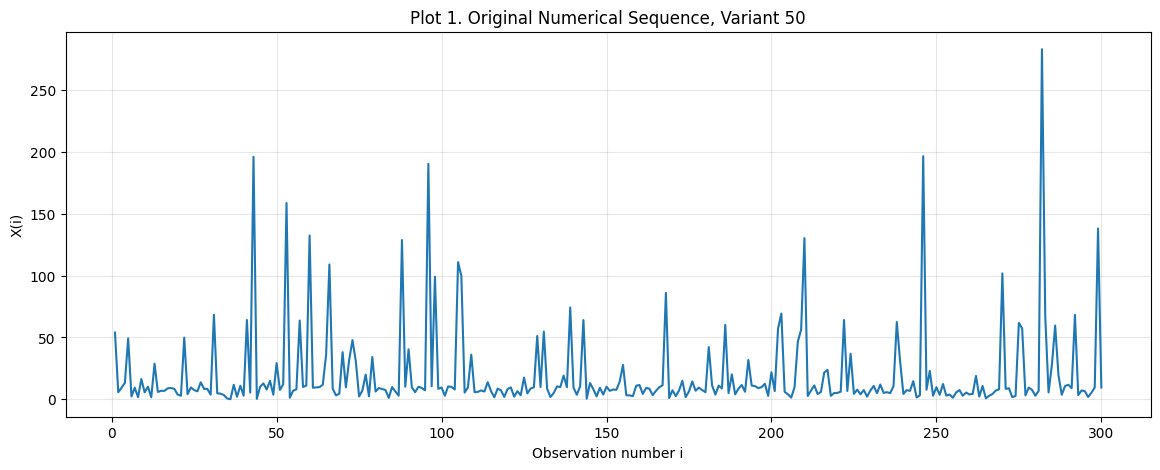

In [9]:
# 7. Plot the original sequence

plt.figure(figsize=(14, 5))
plt.plot(np.arange(1, len(x) + 1), x)
plt.xlabel("Observation number i")
plt.ylabel("X(i)")
plt.title("Plot 1. Original Numerical Sequence, Variant 50")
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
# 8. Simple numerical check for a linear trend

indices = np.arange(1, len(x) + 1)
trend_r = np.corrcoef(indices, x)[0, 1]

print(f"Correlation between observation number and value: r = {trend_r:.6f}")

if abs(trend_r) < 0.2:
    print("The linear trend is weak.")
elif trend_r > 0:
    print("There is a positive linear tendency.")
else:
    print("There is a negative linear tendency.")

Correlation between observation number and value: r = 0.013189
The linear trend is weak.


## 6. Autocorrelation analysis of the original sequence

Autocorrelation coefficients are calculated for lags:

$$
k \in \{1, 2, \ldots, 10\}
$$

As an additional diagnostic reference, approximate random fluctuation limits (95% confidence interval for white noise) can be estimated as:

$$
\pm \frac{1.96}{\sqrt{N}}
$$



In [11]:
# 9. Autocorrelation of the original sequence

lags = np.arange(1, 11)
acf_original = autocorrelation(x, max_lag=10)

acf_original_df = pd.DataFrame({
    "Lag": lags,
    "Original sequence autocorrelation": acf_original,
})

display(acf_original_df)

approx_limit = 1.96 / np.sqrt(len(x))
print(f"Approximate reference limit ±1.96/sqrt(N): ±{approx_limit:.6f}")

,Lag,Original sequence autocorrelation
0,1,-0.000009
1,2,0.009198
2,3,-0.059171
3,4,-0.020707
4,5,-0.066674
5,6,0.026027
6,7,0.125408
7,8,0.067195
8,9,-0.009534
9,10,0.133083


Approximate reference limit ±1.96/sqrt(N): ±0.113161


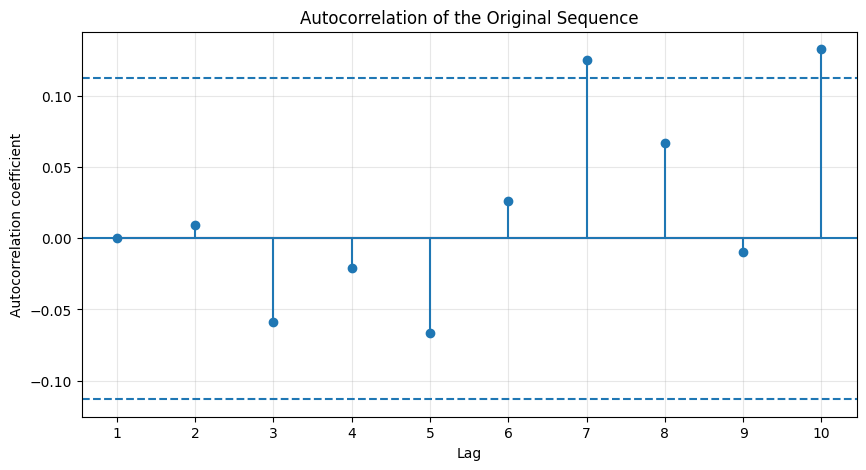

In [12]:
# 10. Plot autocorrelation of the original sequence

plt.figure(figsize=(10, 5))
plt.stem(lags, acf_original)
plt.axhline(0)
plt.axhline(approx_limit, linestyle="--")
plt.axhline(-approx_limit, linestyle="--")
plt.xticks(lags)
plt.xlabel("Lag")
plt.ylabel("Autocorrelation coefficient")
plt.title("Autocorrelation of the Original Sequence")
plt.grid(True, alpha=0.3)
plt.show()

## 7. Plot 2. Frequency histogram of the original sequence

Number of bins using Sturges' rule: 10


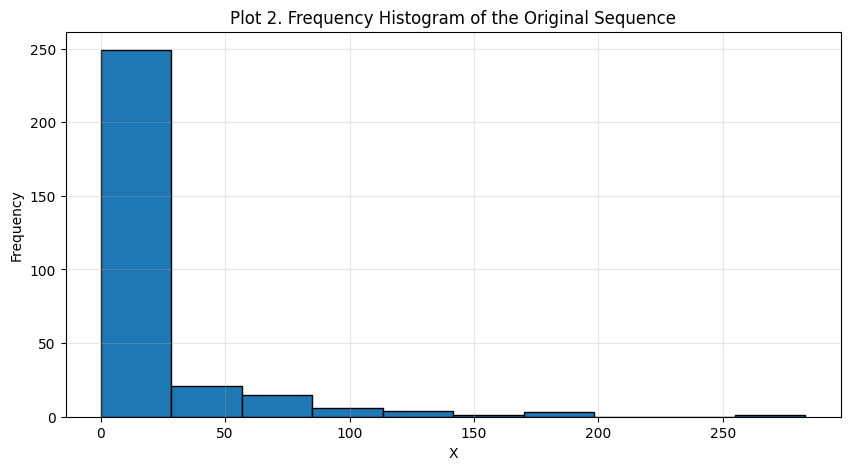

In [13]:
# 11. Histogram of the original sequence

bins_sturges = math.ceil(1 + math.log2(len(x)))

print(f"Number of bins using Sturges' rule: {bins_sturges}")

plt.figure(figsize=(10, 5))
plt.hist(x, bins=bins_sturges, density=False, edgecolor="black")
plt.xlabel("X")
plt.ylabel("Frequency")
plt.title("Plot 2. Frequency Histogram of the Original Sequence")
plt.grid(True, alpha=0.3)
plt.show()

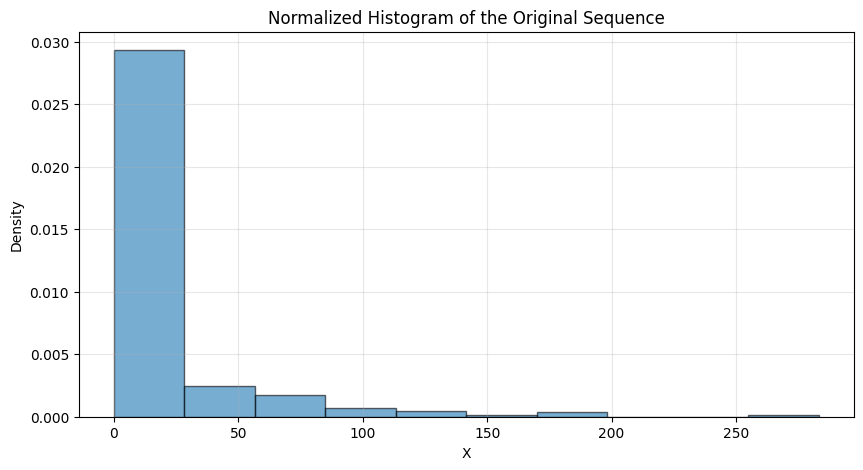

In [14]:
# 12. Normalized histogram

plt.figure(figsize=(10, 5))
plt.hist(x, bins=bins_sturges, density=True, edgecolor="black", alpha=0.6)
plt.xlabel("X")
plt.ylabel("Density")
plt.title("Normalized Histogram of the Original Sequence")
plt.grid(True, alpha=0.3)
plt.show()

## 8. Select an approximating distribution

Ber korte hobe egula

* uniform;
* exponential;
* normalized Erlang;
* hypoexponential;
* hyperexponential.

because the coefficient of variation exceeds unity:

$$
\nu = \frac{\sigma}{m} > 1
$$

i uses a two-phase hyperexponential distribution $H_2$.

A standard two-moment fitting method with balanced means is used

$$
c^2 = \nu^2
$$

$$
p = \frac{1}{2} \left( 1 + \sqrt{\frac{c^2 - 1}{c^2 + 1}} \right)
$$

$$
\lambda_1 = \frac{2p}{m}, \qquad \lambda_2 = \frac{2(1 - p)}{m}
$$

The probability density function is:

$$
f(x) = p\lambda_1 e^{-\lambda_1 x} + (1 - p)\lambda_2 e^{-\lambda_2 x}, \qquad x \ge 0
$$

In [15]:
# 13. Calculate parameters of the approximating distribution

m = original_stats[300]["mean"]
D = original_stats[300]["variance"]
sigma = original_stats[300]["std"]
cv = original_stats[300]["cv"]
scv = cv**2

print(f"Mean m = {m:.6f}")
print(f"Variance D = {D:.6f}")
print(f"Standard deviation sigma = {sigma:.6f}")
print(f"Coefficient of variation nu = {cv:.6f}")
print(f"Squared coefficient of variation nu^2 = {scv:.6f}")

if cv > 1:
    distribution_name = "Two-phase hyperexponential distribution H2"

    p_h2 = 0.5 * (1 + np.sqrt((scv - 1) / (scv + 1)))
    lambda1 = 2 * p_h2 / m
    lambda2 = 2 * (1 - p_h2) / m

    print("\nSelected distribution:", distribution_name)
    print(f"p = {p_h2:.8f}")
    print(f"1-p = {1-p_h2:.8f}")
    print(f"lambda1 = {lambda1:.8f}")
    print(f"lambda2 = {lambda2:.8f}")
else:
    raise ValueError(
        "For these data, nu <= 1. A different approximating distribution should be selected."
    )

Mean m = 19.584811
Variance D = 1184.971639
Standard deviation sigma = 34.423417
Coefficient of variation nu = 1.757659
Squared coefficient of variation nu^2 = 3.089365

Selected distribution: Two-phase hyperexponential distribution H2
p = 0.85739561
1-p = 0.14260439
lambda1 = 0.08755720
lambda2 = 0.01456275


In [16]:
# 14. Verify the theoretical moments of H2

h2_mean_theoretical = p_h2 / lambda1 + (1 - p_h2) / lambda2

h2_second_moment = (
    2 * p_h2 / lambda1**2
    + 2 * (1 - p_h2) / lambda2**2
)

h2_variance_theoretical = h2_second_moment - h2_mean_theoretical**2
h2_std_theoretical = np.sqrt(h2_variance_theoretical)
h2_cv_theoretical = h2_std_theoretical / h2_mean_theoretical

moment_check = pd.DataFrame({
    "Original sequence": [m, D, sigma, cv],
    "Theoretical H2": [
        h2_mean_theoretical,
        h2_variance_theoretical,
        h2_std_theoretical,
        h2_cv_theoretical,
    ],
}, index=[
    "Mean",
    "Variance",
    "Standard deviation",
    "Coefficient of variation",
])

display(moment_check)

,Original sequence,Theoretical H2
Mean,19.584811,19.584811
Variance,1184.971639,1184.971639
Standard deviation,34.423417,34.423417
Coefficient of variation,1.757659,1.757659


## 9. Random variable generator for the \(H_2\) distribution

In [17]:
# 15. H2 random number generator

def generate_h2(size, p, rate1, rate2, rng=None):
    """
    Generate random variables from a two-phase hyperexponential H2 distribution.
    """
    if rng is None:
        rng = np.random.default_rng()

    choose_phase1 = rng.random(size) < p
    result = np.empty(size, dtype=float)

    n1 = np.sum(choose_phase1)
    n2 = size - n1

    result[choose_phase1] = rng.exponential(scale=1 / rate1, size=n1)
    result[~choose_phase1] = rng.exponential(scale=1 / rate2, size=n2)

    return result

# Fixed seed makes the lab results reproducible.
RANDOM_SEED = 50
rng = np.random.default_rng(RANDOM_SEED)

generated = generate_h2(
    size=300,
    p=p_h2,
    rate1=lambda1,
    rate2=lambda2,
    rng=rng,
)

print("First 10 generated values:")
print(generated[:10])
print(f"\nNumber of generated values: {len(generated)}")

First 10 generated values:
[ 2.41951295  0.51067719  9.53018212 61.44427772  2.08785406  5.11629364
 14.59644006  0.17844713 37.70268048  0.19607014]

Number of generated values: 300


## 10. Statistical characteristics of the generated sequence

In [18]:
# 16. Calculate statistics for the generated sequence

generated_stats = {
    n: calc_stats(generated[:n])
    for n in SAMPLE_SIZES
}

generated_summary = pd.DataFrame({
    n: {
        "Mean": generated_stats[n]["mean"],
        "Variance": generated_stats[n]["variance"],
        "Standard deviation": generated_stats[n]["std"],
        "Coefficient of variation": generated_stats[n]["cv"],
        "Half-width p=0.90": generated_stats[n]["eps_0.90"],
        "Half-width p=0.95": generated_stats[n]["eps_0.95"],
        "Half-width p=0.99": generated_stats[n]["eps_0.99"],
    }
    for n in SAMPLE_SIZES
})

display(generated_summary)

,10,20,50,100,200,300
Mean,13.378244,24.001146,22.394142,19.909261,20.314429,20.307052
Variance,416.413170,1134.919579,806.610094,554.465140,816.406983,1008.365892
Standard deviation,20.406204,33.688567,28.400882,23.547083,28.572836,31.754777
Coefficient of variation,1.525328,1.403623,1.268228,1.182720,1.406529,1.563732
Half-width p=0.90,10.602293,12.376707,6.599095,3.868786,3.319525,3.012215
Half-width p=0.95,12.647896,14.764666,7.872323,4.615228,3.959993,3.593391
Half-width p=0.99,16.622950,19.404989,10.346481,6.065729,5.204562,4.722743


## 11. Form 2

The percentage rows compare each characteristic of the **generated sequence** with the corresponding characteristic of the **original sequence** for the same sample size.

In [19]:
# 17. Build Form 2

form2_rows = []

for label, key in metrics:
    values_row = {"Characteristic": label, "Type": "Value"}
    percent_row = {"Characteristic": label, "Type": "%"}

    for n in SAMPLE_SIZES:
        gen_value = generated_stats[n][key]
        orig_value = original_stats[n][key]

        values_row[n] = f"±{gen_value:.6f}" if key.startswith("eps_") else gen_value
        percent_row[n] = relative_deviation(gen_value, orig_value)

    form2_rows.append(values_row)
    form2_rows.append(percent_row)

form2 = pd.DataFrame(form2_rows)
display(form2)

,Characteristic,Type,10,20,50,100,200,300
0,Mean,Value,13.378244,24.001146,22.394142,19.909261,20.314429,20.307052
1,Mean,%,19.836902,86.496831,35.444282,11.739784,9.883990,3.687759
2,Confidence interval (0.90),Value,±10.602293,±12.376707,±6.599095,±3.868786,±3.319525,±3.012215
3,Confidence interval (0.90),%,7.508892,131.346559,7.068546,37.938323,6.448979,7.752396
4,Confidence interval (0.95),Value,±12.647896,±14.764666,±7.872323,±4.615228,±3.959993,±3.593391
5,Confidence interval (0.95),%,7.508892,131.346559,7.068546,37.938323,6.448979,7.752396
6,Confidence interval (0.99),Value,±16.622950,±19.404989,±10.346481,±6.065729,±5.204562,±4.722743
7,Confidence interval (0.99),%,7.508892,131.346559,7.068546,37.938323,6.448979,7.752396
8,Variance,Value,416.413170,1134.919579,806.610094,554.465140,816.406983,1008.365892
9,Variance,%,15.581618,435.212305,13.637448,61.483482,12.482064,14.903795


## 12. Autocorrelation of the generated sequence and Form 3

In [20]:
# 18. Autocorrelation of the generated sequence

acf_generated = autocorrelation(generated, max_lag=10)

acf_compare = pd.DataFrame({
    "Lag": lags,
    "Original sequence autocorrelation": acf_original,
    "Generated sequence autocorrelation": acf_generated,
})

def safe_acf_percent_difference(a, b, eps=1e-12):
    """
    Percentage difference between two autocorrelation coefficients.
    If the reference coefficient is extremely close to zero,
    the relative percentage becomes unstable, so NaN is returned.
    """
    if abs(a) < eps:
        return np.nan
    return abs(b - a) / abs(a) * 100

acf_compare["Difference, %"] = [
    safe_acf_percent_difference(a, b)
    for a, b in zip(acf_original, acf_generated)
]

display(acf_compare)

,Lag,Original sequence autocorrelation,Generated sequence autocorrelation,"Difference, %"
0,1,-0.000009,-0.052987,582833.658962
1,2,0.009198,-0.035048,481.039724
2,3,-0.059171,-0.007386,87.517597
3,4,-0.020707,-0.080149,287.064223
4,5,-0.066674,0.055584,183.367664
5,6,0.026027,-0.048478,286.258367
6,7,0.125408,-0.061960,149.407050
7,8,0.067195,-0.093960,239.833263
8,9,-0.009534,-0.080081,739.938521
9,10,0.133083,-0.042161,131.680280


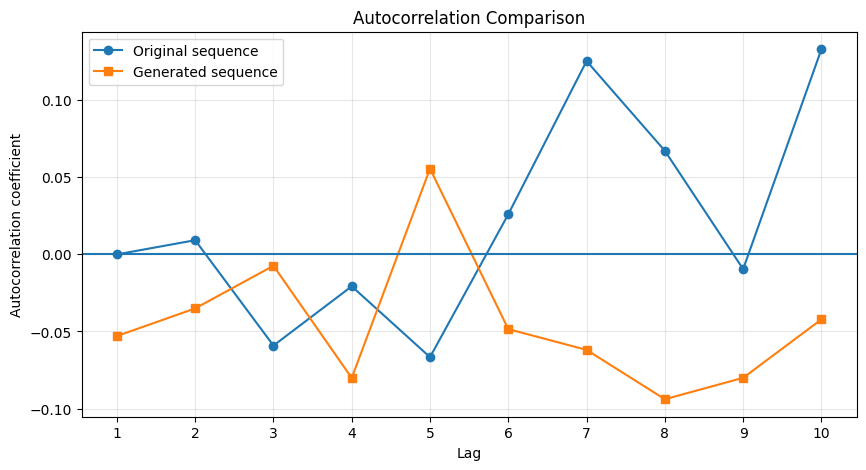

In [21]:
# 19. Compare autocorrelation graphically

plt.figure(figsize=(10, 5))
plt.plot(lags, acf_original, marker="o", label="Original sequence")
plt.plot(lags, acf_generated, marker="s", label="Generated sequence")
plt.axhline(0)
plt.xticks(lags)
plt.xlabel("Lag")
plt.ylabel("Autocorrelation coefficient")
plt.title("Autocorrelation Comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 13. Compare the original and generated sequences

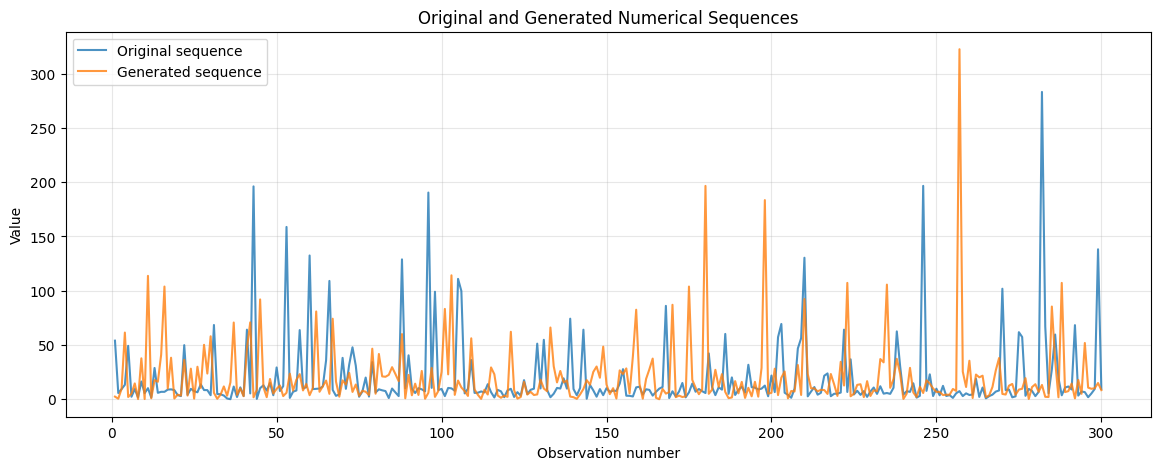

In [22]:
# 20. Plot both sequences

plt.figure(figsize=(14, 5))
plt.plot(np.arange(1, 301), x, label="Original sequence", alpha=0.8)
plt.plot(np.arange(1, 301), generated, label="Generated sequence", alpha=0.8)
plt.xlabel("Observation number")
plt.ylabel("Value")
plt.title("Original and Generated Numerical Sequences")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 14. Plot 3. Original histogram and theoretical density

For the $H_2$ distribution, the theoretical probability density function (PDF) evaluated against the normalized empirical histogram is:

$$
f(x) = p\lambda_1 e^{-\lambda_1 x} + (1 - p)\lambda_2 e^{-\lambda_2 x}
$$

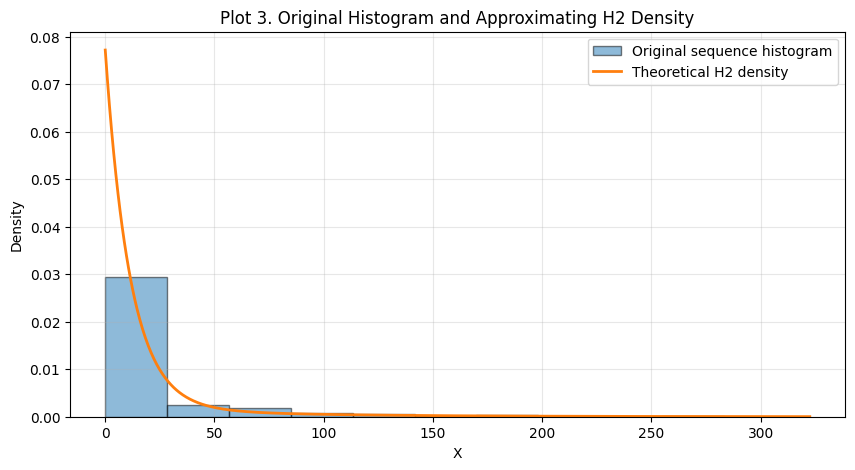

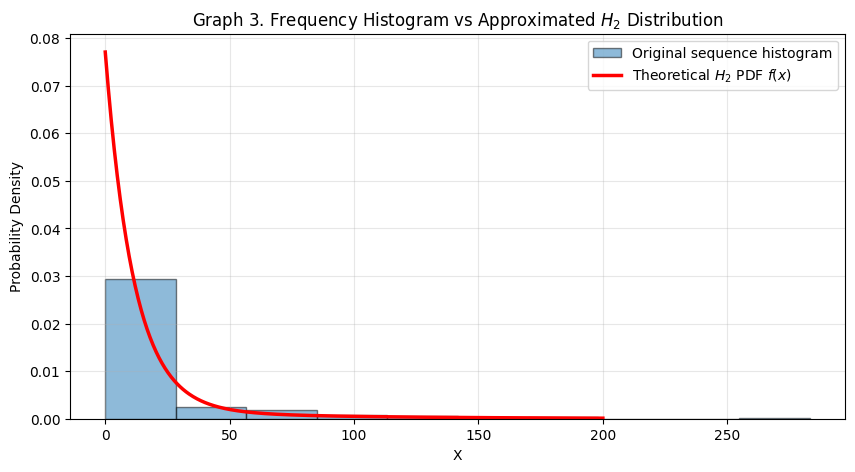

Pearson cross-correlation r_xy: -0.0439
Conclusion: The generated sequence is statistically independent from the original sequence.


In [30]:
# 21. H2 probability density and comparison with the original histogram

def h2_pdf(values, p, rate1, rate2):
    values = np.asarray(values, dtype=float)

    density = (
        p * rate1 * np.exp(-rate1 * values)
        + (1 - p) * rate2 * np.exp(-rate2 * values)
    )

    return np.where(values >= 0, density, 0.0)

grid = np.linspace(0, max(x.max(), generated.max()), 1000)
density_h2 = h2_pdf(grid, p_h2, lambda1, lambda2)

plt.figure(figsize=(10, 5))
plt.hist(
    x,
    bins=bins_sturges,
    density=True,
    edgecolor="black",
    alpha=0.5,
    label="Original sequence histogram",
)
plt.plot(
    grid,
    density_h2,
    linewidth=2,
    label="Theoretical H2 density",
)
plt.xlabel("X")
plt.ylabel("Density")
plt.title("Plot 3. Original Histogram and Approximating H2 Density")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
# 20. Graph 3: Histogram vs Theoretical H2 Probability Density Function
x_grid = np.linspace(0.01, 200, 500)
pdf_h2 = p_h2 * lambda1 * np.exp(-lambda1 * x_grid) + (1 - p_h2) * lambda2 * np.exp(-lambda2 * x_grid)

plt.figure(figsize=(10, 5))
plt.hist(x, bins=bins_sturges, density=True, edgecolor="black", alpha=0.5, label="Original sequence histogram")
plt.plot(x_grid, pdf_h2, "r-", lw=2.5, label="Theoretical $H_2$ PDF $f(x)$")
plt.xlabel("X")
plt.ylabel("Probability Density")
plt.title("Graph 3. Frequency Histogram vs Approximated $H_2$ Distribution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 21. Pearson correlation between original and generated sequence (Item 7c)
r_xy = np.corrcoef(x, generated)[0, 1]
print(f"Pearson cross-correlation r_xy: {r_xy:.4f}")
if abs(r_xy) < 0.1:
    print("Conclusion: The generated sequence is statistically independent from the original sequence.")

## 15. Compare histograms of the original and generated sequences

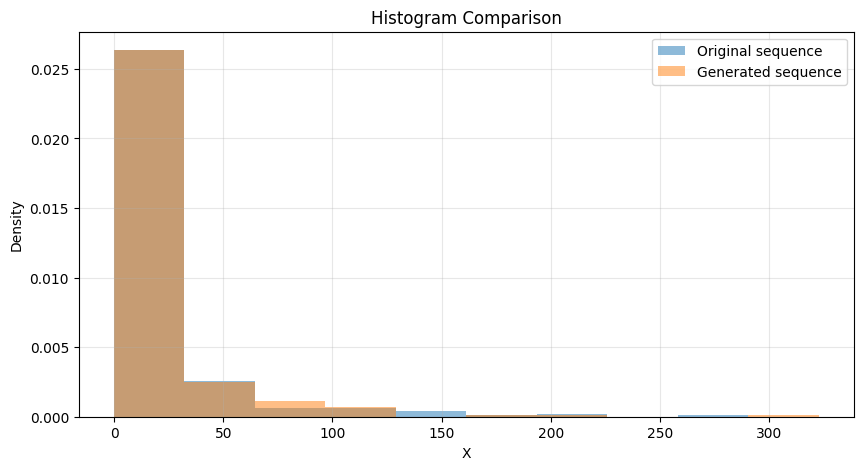

In [24]:
# 22. Histogram comparison

common_max = max(x.max(), generated.max())
common_bins = np.linspace(0, common_max, bins_sturges + 1)

plt.figure(figsize=(10, 5))
plt.hist(
    x,
    bins=common_bins,
    density=True,
    alpha=0.5,
    label="Original sequence",
)
plt.hist(
    generated,
    bins=common_bins,
    density=True,
    alpha=0.5,
    label="Generated sequence",
)
plt.xlabel("X")
plt.ylabel("Density")
plt.title("Histogram Comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 16. Compare the main characteristics for \(n=300\)

In [25]:
# 23. Compare main characteristics for n=300

comparison_300 = pd.DataFrame({
    "Original sequence": [
        original_stats[300]["mean"],
        original_stats[300]["variance"],
        original_stats[300]["std"],
        original_stats[300]["cv"],
    ],
    "Generated sequence": [
        generated_stats[300]["mean"],
        generated_stats[300]["variance"],
        generated_stats[300]["std"],
        generated_stats[300]["cv"],
    ],
}, index=[
    "Mean",
    "Variance",
    "Standard deviation",
    "Coefficient of variation",
])

comparison_300["Deviation, %"] = [
    relative_deviation(
        comparison_300.loc[idx, "Generated sequence"],
        comparison_300.loc[idx, "Original sequence"],
    )
    for idx in comparison_300.index
]

display(comparison_300)

,Original sequence,Generated sequence,"Deviation, %"
Mean,19.584811,20.307052,3.687759
Variance,1184.971639,1008.365892,14.903795
Standard deviation,34.423417,31.754777,7.752396
Coefficient of variation,1.757659,1.563732,11.033275


## 17. Correlation between the original and generated sequences

The sample Pearson correlation coefficient between the original sequence $X$ and the generated sequence $Y$ is defined as:

$$
r_{XY} = \frac{\operatorname{cov}(X, Y)}{\sigma_X \sigma_Y}
$$

Because the generated sequence is independently simulated using pseudo-random numbers, a strong index-by-index linear correlation is not expected ($r_{XY} \approx 0$), confirming sample independence.

In [26]:
# 24. Correlation analysis

cross_corr = np.corrcoef(x, generated)[0, 1]

print(
    "Pearson correlation coefficient between the original "
    f"and generated sequences: r = {cross_corr:.6f}"
)

if abs(cross_corr) < 0.2:
    print("The linear correlation is weak.")
elif abs(cross_corr) < 0.5:
    print("The linear correlation is moderate.")
else:
    print("The linear correlation is noticeable/strong.")

Pearson correlation coefficient between the original and generated sequences: r = -0.043875
The linear correlation is weak.


## 18. Automatically generated numerical conclusions

This cell prints the main numerical results that can be used when writing the report conclusions.

In [27]:
# 25. Automatic numerical conclusions

max_abs_acf_orig = np.max(np.abs(acf_original))
max_abs_acf_gen = np.max(np.abs(acf_generated))


print("1. ORIGINAL SEQUENCE")
print(
    f"For n=300: mean={original_stats[300]['mean']:.4f}, "
    f"variance={original_stats[300]['variance']:.4f}, "
    f"std={original_stats[300]['std']:.4f}, "
    f"cv={original_stats[300]['cv']:.4f}."
)

print("\n2. CONFIDENCE INTERVALS")
for p in [0.90, 0.95, 0.99]:
    eps = original_stats[300][f"eps_{p:.2f}"]
    low = original_stats[300][f"ci_{p:.2f}_low"]
    high = original_stats[300][f"ci_{p:.2f}_high"]
    print(
        f"p={p:.2f}: ±{eps:.4f}; "
        f"full interval ({low:.4f}; {high:.4f})"
    )

print("\n3. AUTOCORRELATION")
print(f"Maximum |r_k| for the original sequence, lags 1..10: {max_abs_acf_orig:.4f}")
print(f"Approximate reference limit ±1.96/sqrt(N): {approx_limit:.4f}")

if max_abs_acf_orig <= approx_limit:
    print("All calculated autocorrelation coefficients are within the approximate random-fluctuation limits.")
else:
    print("Some autocorrelation coefficients exceed the approximate limits and should be discussed.")

print("\n4. APPROXIMATING DISTRIBUTION")
print(
    f"cv={cv:.4f} > 1, therefore an H2 hyperexponential approximation is used."
)
print(
    f"p={p_h2:.6f}, lambda1={lambda1:.6f}, lambda2={lambda2:.6f}."
)

print("\n5. GENERATED SEQUENCE")
print(
    f"For n=300: mean={generated_stats[300]['mean']:.4f}, "
    f"variance={generated_stats[300]['variance']:.4f}, "
    f"std={generated_stats[300]['std']:.4f}, "
    f"cv={generated_stats[300]['cv']:.4f}."
)

print("\n6. CORRELATION BETWEEN THE TWO SEQUENCES")
print(f"r={cross_corr:.4f}")

print("\n7. FINAL INTERPRETATION")
print(
    "Approximation quality should be evaluated using several criteria together: "
    "similarity of moments, histogram shape versus theoretical density, "
    "and autocorrelation behavior."
)

1. ORIGINAL SEQUENCE
For n=300: mean=19.5848, variance=1184.9716, std=34.4234, cv=1.7577.

2. CONFIDENCE INTERVALS
p=0.90: ±3.2654; full interval (16.3195; 22.8502)
p=0.95: ±3.8954; full interval (15.6894; 23.4802)
p=0.99: ±5.1196; full interval (14.4652; 24.7044)

3. AUTOCORRELATION
Maximum |r_k| for the original sequence, lags 1..10: 0.1331
Approximate reference limit ±1.96/sqrt(N): 0.1132
Some autocorrelation coefficients exceed the approximate limits and should be discussed.

4. APPROXIMATING DISTRIBUTION
cv=1.7577 > 1, therefore an H2 hyperexponential approximation is used.
p=0.857396, lambda1=0.087557, lambda2=0.014563.

5. GENERATED SEQUENCE
For n=300: mean=20.3071, variance=1008.3659, std=31.7548, cv=1.5637.

6. CORRELATION BETWEEN THE TWO SEQUENCES
r=-0.0439

7. FINAL INTERPRETATION
Approximation quality should be evaluated using several criteria together: similarity of moments, histogram shape versus theoretical density, and autocorrelation behavior.


## 19. Export results to Excel


In [28]:
output_excel = "Lab1_Variant50_results.xlsx"

with pd.ExcelWriter(output_excel, engine="openpyxl") as writer:
    pd.DataFrame({"Original": x}).to_excel(
        writer, sheet_name="Original_Data", index=False
    )
    pd.DataFrame({"Generated": generated}).to_excel(
        writer, sheet_name="Generated_Data", index=False
    )
    original_summary.to_excel(writer, sheet_name="Original_Stats")
    generated_summary.to_excel(writer, sheet_name="Generated_Stats")
    form1.to_excel(writer, sheet_name="Form1", index=False)
    form2.to_excel(writer, sheet_name="Form2", index=False)
    acf_compare.to_excel(writer, sheet_name="Form3_ACF", index=False)
    comparison_300.to_excel(writer, sheet_name="Comparison_300")
    ci_original.to_excel(writer, sheet_name="Confidence_Intervals", index=False)

print(f"Results saved to: {output_excel}")

Results saved to: Lab1_Variant50_results.xlsx
